# 05. Baseline models

**Goal:** measure how much signal the posting-time features carry for predicting `is_viral`.

**Models:** logistic regression (simple baseline), then LightGBM (gradient boosted trees).
**Metrics:** PR-AUC (compared with the random baseline of about 0.10), ROC-AUC, and recall in the
top 10% of ranked videos (random would give 0.10). Accuracy is not used because of class imbalance.
**Protocol:** tune on validation only. The test set is evaluated once, at the very end.
**Expectation:** modest scores, because the data has no creator information (followers, past views).

## 1. Load data and define features

In [3]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
from sklearn.metrics import average_precision_score, roc_auc_score

ROOT = Path.cwd().parent
P = ROOT / "data" / "processed"

tr = pl.read_parquet(P / "train_features.parquet").to_pandas()
va = pl.read_parquet(P / "validation_features.parquet").to_pandas()
te = pl.read_parquet(P / "test_features.parquet").to_pandas()

for d in (tr, va, te):
    d["sound_log"] = np.log1p(d["sound_freq"])

CAT = ["country", "language", "type"]
NUM = ["hour", "weekday", "duration_ms", "image_count", "caption_len", "caption_words",
       "n_hashtags", "n_mentions", "n_onscreen", "is_ad", "is_shop_video", "is_branded", "sound_log"]

# Features removed after the exploratory analysis:
# caption_words duplicates caption_len; image_count and is_branded had zero importance.
DROP = ["caption_words", "image_count", "is_branded"]
NUM = [c for c in NUM if c not in DROP]
FEATS = CAT + NUM

y_tr, y_va, y_te = tr["is_viral"], va["is_viral"], te["is_viral"]
print("positive rate train / validation / test:", y_tr.mean().round(4), y_va.mean().round(4), y_te.mean().round(4))
print("features used:", FEATS)

def report(name, y, p):
    ap = average_precision_score(y, p)
    auc = roc_auc_score(y, p)
    k = int(len(y) * 0.10)
    top = np.argsort(-p)[:k]
    rec = y.values[top].sum() / y.sum()
    print(f"{name}: PR-AUC {ap:.3f} (random = {y.mean():.3f}) | ROC-AUC {auc:.3f} | recall in top 10% {rec:.3f}")

positive rate train / validation / test: 0.0997 0.1001 0.1012
features used: ['country', 'language', 'type', 'hour', 'weekday', 'duration_ms', 'caption_len', 'n_hashtags', 'n_mentions', 'n_onscreen', 'is_ad', 'is_shop_video', 'sound_log']


`month` is left out on purpose: train only covers Jan to Sep 2025, so the model could not learn
seasonality that carries over to 2026.

## 2. Baseline: logistic regression

A weighted sum of the features converted to a probability. It can only learn straight-line effects.
It needs one-hot encoding for categories and scaling for numbers. `class_weight="balanced"` makes
errors on the rare viral class count more.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT),
    ("num", StandardScaler(), NUM),
])
logit = make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight="balanced"))
logit.fit(tr[FEATS], y_tr)
report("LogReg  validation", y_va, logit.predict_proba(va[FEATS])[:, 1])

LogReg  validation: PR-AUC 0.172 (random = 0.100) | ROC-AUC 0.680 | recall in top 10% 0.213


## 3. LightGBM

Gradient boosting: hundreds of small decision trees, each one correcting the errors of the previous ones.
It captures non-linear effects and interactions and handles categories directly.
Early stopping stops adding trees when the validation PR-AUC stops improving for 100 rounds.

In [5]:
import lightgbm as lgb

cats = {c: sorted(tr[c].unique()) for c in CAT}

def prep(d):
    X = d[FEATS].copy()
    for c in CAT:
        # values not seen in train become missing instead of raising a warning
        X[c] = pd.Categorical(X[c].where(X[c].isin(cats[c])), categories=cats[c])
    return X

Xtr, Xva, Xte = prep(tr), prep(va), prep(te)

gbm = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1,
)
gbm.fit(Xtr, y_tr, eval_set=[(Xva, y_va)], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)])
print("best iteration:", gbm.best_iteration_)
report("LightGBM validation", y_va, gbm.predict_proba(Xva)[:, 1])

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[196]	valid_0's average_precision: 0.203731	valid_0's binary_logloss: 0.301156
best iteration: 196
LightGBM validation: PR-AUC 0.204 (random = 0.100) | ROC-AUC 0.709 | recall in top 10% 0.244


## 4. Feature importance (table)

In [6]:
imp = pd.Series(gbm.booster_.feature_importance("gain"), index=FEATS).sort_values(ascending=False)
print((imp / imp.sum()).round(3))

caption_len      0.351
duration_ms      0.199
n_hashtags       0.087
hour             0.078
language         0.074
n_onscreen       0.059
country          0.043
weekday          0.042
n_mentions       0.022
is_ad            0.021
sound_log        0.018
type             0.004
is_shop_video    0.004
dtype: float64


## 5. Evaluation graphs (validation set)

### 5.1 Precision-Recall and ROC curves

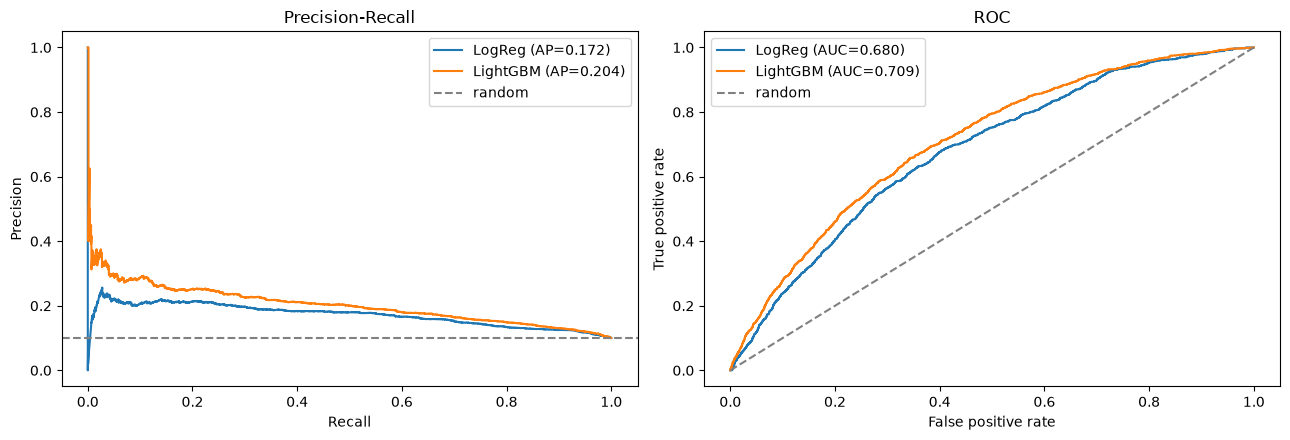

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

p_log = logit.predict_proba(va[FEATS])[:, 1]
p_gbm = gbm.predict_proba(Xva)[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in [("LogReg", p_log), ("LightGBM", p_gbm)]:
    pr, rc, _ = precision_recall_curve(y_va, p)
    ax[0].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_va, p):.3f})")
    fpr, tpr, _ = roc_curve(y_va, p)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_va, p):.3f})")
ax[0].axhline(y_va.mean(), ls="--", color="gray", label="random")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision-Recall"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], ls="--", color="gray", label="random")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title("ROC"); ax[1].legend()
plt.tight_layout(); plt.show()

### Model Performance Comparison

The Precision-Recall and ROC curves compare the performance of Logistic Regression (LogReg) and LightGBM (LightGBM) in distinguishing between the two classes.

#### Precision-Recall Curve
The Precision-Recall curves show that LightGBM performs slightly better than Logistic Regression across most recall levels. LightGBM achieves an Average Precision (AP) of **0.204**, compared with **0.172** for Logistic Regression. Both models perform above the random baseline (approximately 0.10), indicating that they capture useful patterns for identifying positive cases. However, their precision remains relatively low, especially as recall increases, meaning that detecting more positive cases comes at the cost of generating more false positives.

#### ROC Curve
The ROC curves also show a slight advantage for LightGBM, with an AUC of **0.709**, compared with **0.680** for Logistic Regression. Both curves lie above the random classifier baseline, confirming that the models have some ability to distinguish positive cases from negative ones. Nevertheless, their AUC values indicate moderate discriminative performance rather than strong separation.

#### Overall Interpretation
Overall, LightGBM outperforms Logistic Regression on both evaluation metrics. It achieves better ranking of positive cases and slightly stronger discrimination between the two classes. However, the improvement is relatively modest, and both models still have limited predictive performance. LightGBM could therefore be preferred as the current model, while further improvements in feature engineering, class imbalance handling, hyperparameter tuning, and threshold selection could help improve its effectiveness.

Question :
Is LightGBM above logistic regression everywhere, or only in some zones? How far are both above the random line?

### 5.2 Lift chart: actual viral rate by decile of predicted score

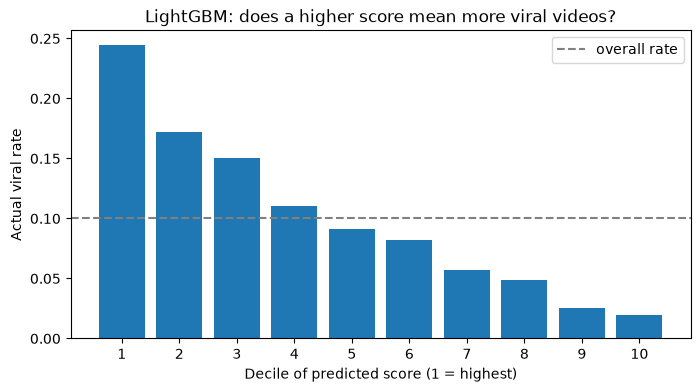

decile
1     0.244
2     0.172
3     0.150
4     0.110
5     0.091
6     0.082
7     0.057
8     0.049
9     0.026
10    0.019
Name: y, dtype: float64


In [14]:
d = pd.DataFrame({"y": y_va.values, "p": p_gbm})
d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = d.groupby("decile", observed=True)["y"].mean()


plt.figure(figsize=(8, 4))
plt.bar(lift.index.astype(str), lift.values)
plt.axhline(y_va.mean(), ls="--", color="gray", label="overall rate")
plt.xlabel("Decile of predicted score (1 = highest)"); plt.ylabel("Actual viral rate")
plt.title("LightGBM: does a higher score mean more viral videos?"); plt.legend(); 
plt.savefig(ROOT / "reports" / "lift_chart.png", dpi=150, bbox_inches="tight")
plt.show()
print(lift.round(3))

The graph shows a clear inverse relationship between the predicted score and the actual viral rate. Videos in the highest-scored decile (1) have a viral rate of 24.4%, more than twice the overall rate of 10%. As the decile decreases in priority, the viral rate steadily declines, reaching 1.9% in decile 10. This indicates that LightGBM effectively ranks videos by their likelihood of going viral, making it useful for prioritizing high-potential videos.

Question ?
How much higher is decile 1 than the dashed line? Do the bars decrease steadily? What does decile 10 tell you?

### 5.3 Feature importance (graph)

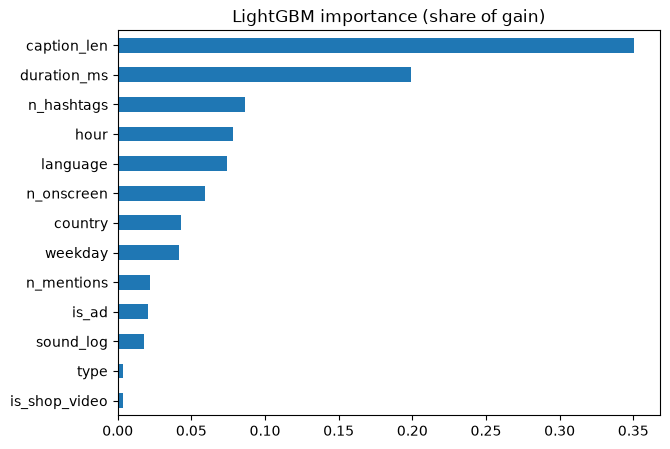

In [9]:
imp = pd.Series(gbm.booster_.feature_importance("gain"), index=FEATS).sort_values()
(imp / imp.sum()).plot.barh(figsize=(7, 5), title="LightGBM importance (share of gain)")
plt.show()

**My interpretation : Caption length is the most important feature, accounting for approximately 35% of the model’s total gain, followed by video duration at about 20%. Hashtag count, posting hour, and language contribute moderately, while video type and shop-video status contribute very little. The model therefore relies most heavily on caption length and duration when making predictions. These importance scores indicate predictive contribution—not whether a feature increases or decreases the predicted outcome, or whether its effect is causal.

Which features lead? Which ones overlap (caption length, hashtags, language)? Remember: association, not cause.

### 5.4 Validation score during training

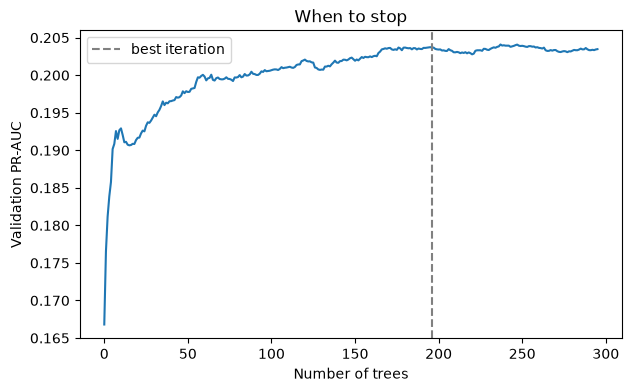

In [10]:
res = gbm.evals_result_["valid_0"]["average_precision"]
plt.figure(figsize=(7, 4))
plt.plot(res)
plt.axvline(gbm.best_iteration_, ls="--", color="gray", label="best iteration")
plt.xlabel("Number of trees"); plt.ylabel("Validation PR-AUC"); plt.title("When to stop"); plt.legend()
plt.show()

**My interpretation** : The model has largely converged by ~200 trees. Continuing to 300 trees does not hurt the validation score much (no strong overfitting visible yet), but it also does not help.
Using the model at the best iteration (≈200 trees) is the rational choice: you get essentially the maximum validation performance with a smaller, faster model.
The fact that the curve stays flat rather than declining is a good sign — the model is not clearly overfitting in the range shown.
At which tree does the curve peak? What happens after, and why does early stopping matter?

## 6. Is the difference between the models real? (uncertainty)

### 6.1 Paired bootstrap: LightGBM minus logistic regression

In [11]:
rng = np.random.default_rng(0)
diffs = []
for _ in range(500):
    idx = rng.integers(0, len(y_va), len(y_va))
    yy = y_va.values[idx]
    diffs.append(average_precision_score(yy, p_gbm[idx]) - average_precision_score(yy, p_log[idx]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"PR-AUC gain of LightGBM over LogReg: mean {np.mean(diffs):.3f}, 95% interval [{lo:.3f}, {hi:.3f}]")

PR-AUC gain of LightGBM over LogReg: mean 0.032, 95% interval [0.022, 0.043]


The gain is 0.032 with a 95% interval [0.022, 0.043].Because the entire interval lies well above 0, the improvement of LightGBM over logistic regression is statistically significant — LightGBM is clearly better on PR-AUC.

### 6.2 Uncertainty of the LightGBM PR-AUC

In [12]:
rng = np.random.default_rng(0)
aps = []
for _ in range(200):
    idx = rng.integers(0, len(y_va), len(y_va))
    aps.append(average_precision_score(y_va.values[idx], p_gbm[idx]))
print("LightGBM PR-AUC 95% interval:", np.percentile(aps, [2.5, 97.5]).round(3))

LightGBM PR-AUC 95% interval: [0.188 0.223]


## 7. Final test evaluation (run ONCE, at the very end)

Do not change the features, the model or its settings after seeing this result.
Validation was used for early stopping, so a test score slightly below validation is normal.

In [13]:
p_te = gbm.predict_proba(Xte)[:, 1]
report("LightGBM TEST", y_te, p_te)

rng = np.random.default_rng(1)
aps_te = [average_precision_score(y_te.values[i], p_te[i])
          for i in (rng.integers(0, len(y_te), len(y_te)) for _ in range(200))]
print("TEST PR-AUC 95% interval:", np.percentile(aps_te, [2.5, 97.5]).round(3))

LightGBM TEST: PR-AUC 0.214 (random = 0.101) | ROC-AUC 0.719 | recall in top 10% 0.248
TEST PR-AUC 95% interval: [0.201 0.231]


## 8. Conclusion of the baseline models

On validation, LightGBM (PR-AUC about 0.20) outperforms logistic regression (about 0.17) and about
doubles the random baseline of 0.10. Ranking videos by predicted score, the top decile contains about
24% viral videos and the bottom decile about 2%.
On the test set, LightGBM reaches PR-AUC 0.214 (95% interval [0.201, 0.231]) and recall in the top 10% of 0.248.
Caption features (length, hashtags, language) carry about half of the importance, followed by duration
and posting hour. These are associations, not causes.

**Limits.** No creator information (followers, past performance) is available, which is usually the
strongest driver of virality, so the signal is modest. Validation was used for early stopping, so
validation scores are slightly optimistic. The test set was used once.

**Next steps.** Caption text features (TF-IDF), robustness check with the top 5% label, and an
out-of-time check on the 2024 sample.